In [2]:
import geopandas as gpd

url = "https://www2.census.gov/geo/tiger/TIGER2024/PLACE/tl_2024_53_place.zip"
wa = gpd.read_file(url)
wa.head()

,STATEFP,PLACEFP,PLACENS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,PCICBSA,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,53,68435,02412001,5368435,1600000US5368435,Sumner,Sumner city,25,C1,N,G4110,A,19563878,316619,+47.2272148,-122.2362644,"MULTIPOLYGON (((-122.20028 47.19192, -122.2000..."
1,53,43395,02412955,5343395,1600000US5343395,Marcus,Marcus town,43,C1,N,G4110,A,568030,0,+48.6642976,-118.0599698,"POLYGON ((-118.07286 48.6629, -118.07286 48.66..."
2,53,07380,02409882,5307380,1600000US5307380,Bothell,Bothell city,25,C1,N,G4110,A,35314956,0,+47.7735313,-122.2043759,"POLYGON ((-122.24927 47.80244, -122.24918 47.8..."
3,53,33175,02412790,5333175,1600000US5333175,Index,Index town,43,C1,N,G4110,A,594868,0,+47.8212624,-121.5559291,"POLYGON ((-121.56338 47.82096, -121.56332 47.8..."
4,53,63210,02411859,5363210,1600000US5363210,Sedro-Woolley,Sedro-Woolley city,25,C1,N,G4110,A,11258239,0,+48.5113562,-122.2321368,"MULTIPOLYGON (((-122.21295 48.50322, -122.2127..."


In [3]:
cities = ["Federal Way", "Seattle", "Tacoma", "Kent", "Auburn", "Des Moines",
          "Renton", "Burien", "SeaTac", "Tukwila", "Puyallup", "Fife",
          "Milton", "Lakewood"]

region = wa[wa["NAME"].isin(cities)]
region

,STATEFP,PLACEFP,PLACENS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,PCICBSA,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
41,53,56695,02411504,5356695,1600000US5356695,Puyallup,Puyallup city,25,C1,N,G4110,A,37201995,283669,+47.1790463,-122.2915230,"MULTIPOLYGON (((-122.28388 47.20866, -122.2828..."
50,53,46020,02411114,5346020,1600000US5346020,Milton,Milton city,25,C1,N,G4110,A,7204260,98909,+47.2519937,-122.3172889,"POLYGON ((-122.34026 47.26104, -122.34012 47.2..."
61,53,08850,02409940,5308850,1600000US5308850,Burien,Burien city,25,C1,N,G4110,A,26000614,2981432,+47.4756052,-122.3446615,"POLYGON ((-122.38738 47.45174, -122.38587 47.4..."
63,53,72625,02412106,5372625,1600000US5372625,Tukwila,Tukwila city,25,C1,N,G4110,A,23788090,1069363,+47.4762890,-122.2757402,"POLYGON ((-122.31846 47.53177, -122.31826 47.5..."
120,53,23795,02410502,5323795,1600000US5323795,Fife,Fife city,25,C1,N,G4110,A,15109857,336136,+47.2322930,-122.3506106,"POLYGON ((-122.39963 47.24046, -122.39963 47.2..."
127,53,38038,02411615,5338038,1600000US5338038,Lakewood,Lakewood city,25,C1,Y,G4110,A,44184014,4744533,+47.1640919,-122.5281062,"POLYGON ((-122.57942 47.16638, -122.5793 47.16..."
128,53,70000,02412025,5370000,1600000US5370000,Tacoma,Tacoma city,25,C1,Y,G4110,A,128780243,32921338,+47.2521991,-122.4598318,"MULTIPOLYGON (((-122.5139 47.22828, -122.51306..."
144,53,03180,02409755,5303180,1600000US5303180,Auburn,Auburn city,25,C1,Y,G4110,A,76598921,748525,+47.3037730,-122.2100001,"POLYGON ((-122.28058 47.31432, -122.28046 47.3..."
149,53,23515,02410494,5323515,1600000US5323515,Federal Way,Federal Way city,25,C1,N,G4110,A,57794909,3636747,+47.3115960,-122.3377572,"POLYGON ((-122.42321 47.32402, -122.41559 47.3..."
153,53,57745,02410926,5357745,1600000US5357745,Renton,Renton city,25,C1,Y,G4110,A,60969485,4467828,+47.4791902,-122.1946129,"MULTIPOLYGON (((-122.23145 47.49004, -122.2314..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

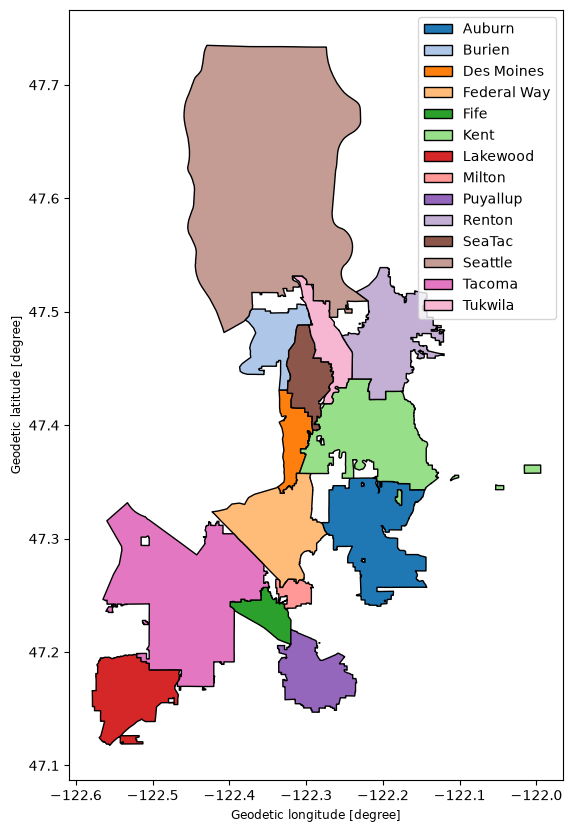

In [4]:
region.plot(column="NAME", legend=True, figsize=(8, 10), edgecolor="black")

In [6]:
region.explore(column="NAME", tiles="CartoDB positron")

/Users/shaelimtiaco/miniconda3/envs/gis/lib/python3.12/site-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


In [7]:
print(region.crs)

region_sp = region.to_crs(2927)
region_sp["sq_miles"] = region_sp.area / 27878400
region_sp[["NAME", "sq_miles"]].sort_values("sq_miles", ascending=False)

EPSG:4269


,NAME,sq_miles
258,Seattle,142.094342
128,Tacoma,62.431058
190,Kent,34.416895
144,Auburn,29.863547
153,Renton,25.267206
149,Federal Way,23.718511
127,Lakewood,18.890234
41,Puyallup,14.472557
61,Burien,11.190795
155,SeaTac,10.240067


In [8]:
region.to_file("puget_sound_cities.geojson")